## Gradient descent for linear regression: the math

Let $n$ be the number of samples, $p$ the number of features, $X \in \mathbb{R}^{n \times p}$ the (standardized) feature matrix, $y \in \mathbb{R}^{n}$ the target, $w \in \mathbb{R}^{p}$ the weights, and $b$ the bias.

**Prediction**

$$\hat{y} = Xw + b$$

**Loss (mean squared error)**

$$L(w, b) = \frac{1}{n}\sum_{i=1}^{n}\left(\hat{y}_i - y_i\right)^2$$

**Gradients**

Let $r = \hat{y} - y$ be the residual vector, so $L = \frac{1}{n}\, r^{\top} r$.

Since $\hat{y}_i = \sum_j x_{ij} w_j + b$, we have $\frac{\partial r_i}{\partial w_j} = x_{ij}$ and $\frac{\partial r_i}{\partial b} = 1$. Applying the chain rule:

$$\frac{\partial L}{\partial w_j} = \frac{2}{n}\sum_{i=1}^{n} r_i\, x_{ij}
\quad\Longrightarrow\quad
\frac{\partial L}{\partial w} = \frac{2}{n}\, X^{\top}(\hat{y} - y)$$

$$\frac{\partial L}{\partial b} = \frac{2}{n}\sum_{i=1}^{n}\left(\hat{y}_i - y_i\right)$$

**Parameter update** (learning rate $\eta$)

$$w \leftarrow w - \eta\,\frac{\partial L}{\partial w}, \qquad
b \leftarrow b - \eta\,\frac{\partial L}{\partial b}$$

**Procedure**
1. Standardize the features (mean and standard deviation computed on the training set only).
2. Initialize $w = 0$ and $b = 0$.
3. For a fixed number of iterations: record the loss, compute the gradients, then update $w$ and $b$.
4. Compare the final $w$ and $b$ with scikit-learn's `LinearRegression` fitted on the same standardized data.

**Why this should work:** the MSE loss for linear regression is convex, so gradient descent with a small enough learning rate approaches the same minimum that a direct least-squares solver finds. The scratch implementation is compared with scikit-learn by its resulting solution and prediction performance, not by its internal method.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

data = load_diabetes(as_frame=True)
X, y = data.data, data.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler().fit(X_train)          # statistics from training data only
Xtr = scaler.transform(X_train)
Xte = scaler.transform(X_test)
ytr, yte = y_train.values, y_test.values
print(Xtr.shape, Xte.shape)                      # (353, 10) (89, 10)

(353, 10) (89, 10)


In [2]:
def predict(X, w, b):
    return X @ w + b

def mse_loss(X, y, w, b):
    r = predict(X, w, b) - y
    return np.mean(r ** 2)

def gradients(X, y, w, b):
    n = len(y)
    r = predict(X, w, b) - y
    grad_w = (2 / n) * (X.T @ r)
    grad_b = (2 / n) * r.sum()
    return grad_w, grad_b

def gradient_descent(X, y, lr, n_iter):
    w = np.zeros(X.shape[1])     # step 51: initialize parameters
    b = 0.0
    losses, w_hist = [], []
    for _ in range(n_iter):
        losses.append(mse_loss(X, y, w, b))      # step 54: loss every iteration
        w_hist.append(w.copy())
        gw, gb = gradients(X, y, w, b)
        w = w - lr * gw                           # step 52: learning rate x gradient
        b = b - lr * gb
    return w, b, np.array(losses), np.array(w_hist)

In [3]:
rng = np.random.RandomState(0)
w0, b0 = rng.randn(10), 1.0
gw, gb = gradients(Xtr, ytr, w0, b0)

eps = 1e-5
num_gw = np.array([
    (mse_loss(Xtr, ytr, w0 + eps * np.eye(10)[j], b0) -
     mse_loss(Xtr, ytr, w0 - eps * np.eye(10)[j], b0)) / (2 * eps)
    for j in range(10)
])
num_gb = (mse_loss(Xtr, ytr, w0, b0 + eps) - mse_loss(Xtr, ytr, w0, b0 - eps)) / (2 * eps)

print("max |analytic - numeric| for w:", np.abs(gw - num_gw).max())
print("|analytic - numeric| for b:", abs(gb - num_gb))

max |analytic - numeric| for w: 3.534670440785703e-07
|analytic - numeric| for b: 2.664495468707173e-08


In [4]:
LR, N_ITER = 0.1, 10000
w_gd, b_gd, losses, w_hist = gradient_descent(Xtr, ytr, LR, N_ITER)
print("Initial loss:", losses[0])
print("Final loss:  ", losses[-1])

Initial loss: 29711.32294617564
Final loss:   2868.5497028355776


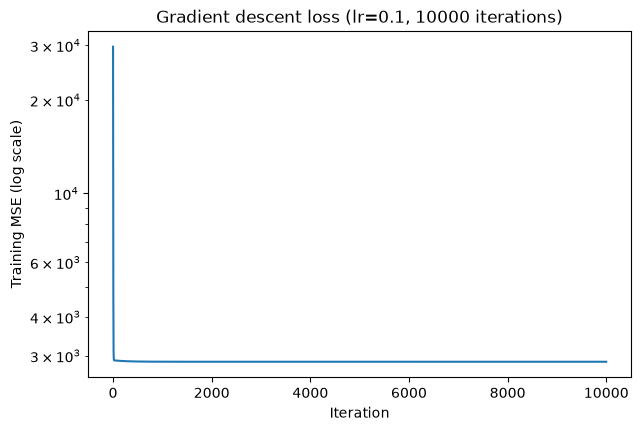

In [5]:
plt.figure(figsize=(7, 4.5))
plt.plot(losses)
plt.yscale("log")
plt.xlabel("Iteration")
plt.ylabel("Training MSE (log scale)")
plt.title(f"Gradient descent loss (lr={LR}, {N_ITER} iterations)")
plt.savefig("D:/Research Project/results/figures/gd_loss_curve.png", dpi=150, bbox_inches="tight")
plt.show()

In [6]:
sk = LinearRegression().fit(Xtr, y_train)

pred_gd = predict(Xte, w_gd, b_gd)
pred_sk = sk.predict(Xte)

comparison = pd.DataFrame({
    "sklearn": np.append(sk.coef_, sk.intercept_),
    "gradient_descent": np.append(w_gd, b_gd),
}, index=list(X.columns) + ["intercept"])
comparison["abs_diff"] = (comparison.sklearn - comparison.gradient_descent).abs()
comparison.to_csv("D:/Research Project/results/tables/gd_vs_sklearn_coefficients.csv")
display(comparison.round(4))

metrics = pd.DataFrame({
    "train_MSE": [mse_loss(Xtr, ytr, sk.coef_, sk.intercept_), losses[-1]],
    "test_RMSE": [np.sqrt(mean_squared_error(yte, pred_sk)), np.sqrt(mean_squared_error(yte, pred_gd))],
    "test_R2":   [r2_score(yte, pred_sk), r2_score(yte, pred_gd)],
}, index=["sklearn", "gradient_descent"])
metrics.to_csv("D:/Research Project/results/tables/gd_vs_sklearn_metrics.csv")
display(metrics.round(4))
print("max |test prediction difference|:", np.abs(pred_gd - pred_sk).max())

,sklearn,gradient_descent,abs_diff
age,1.7538,1.7538,0.0
sex,-11.5118,-11.5118,0.0
bmi,25.6071,25.6071,0.0
bp,16.8289,16.8289,0.0
s1,-44.4489,-44.4489,0.0
s2,24.6410,24.6410,0.0
s3,7.6770,7.6770,0.0
s4,13.1388,13.1388,0.0
s5,35.1612,35.1612,0.0
s6,2.3514,2.3514,0.0


,train_MSE,test_RMSE,test_R2
sklearn,2868.5497,53.8534,0.4526
gradient_descent,2868.5497,53.8534,0.4526


max |test prediction difference|: 1.1242924813359423e-07


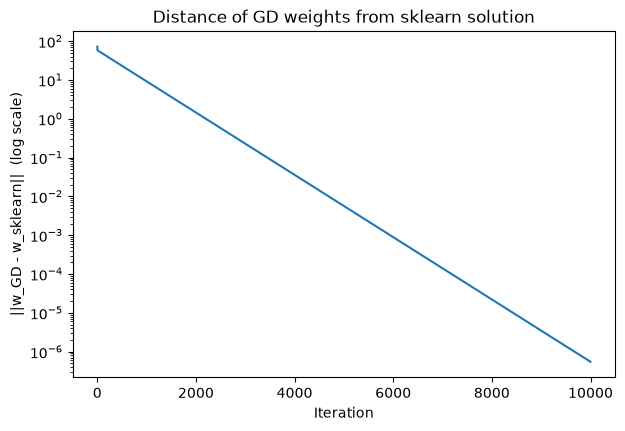

In [7]:
dist = np.linalg.norm(w_hist - sk.coef_, axis=1)
plt.figure(figsize=(7, 4.5))
plt.plot(dist)
plt.yscale("log")
plt.xlabel("Iteration")
plt.ylabel("||w_GD - w_sklearn||  (log scale)")
plt.title("Distance of GD weights from sklearn solution")
plt.savefig("D:/Research Project/results/figures/gd_coef_distance.png", dpi=150, bbox_inches="tight")
plt.show()

d:\Research Project\.venv\Lib\site-packages\matplotlib\scale.py:375: RuntimeWarning: overflow encountered in exp
  return np.exp(values * np.log(self.base))


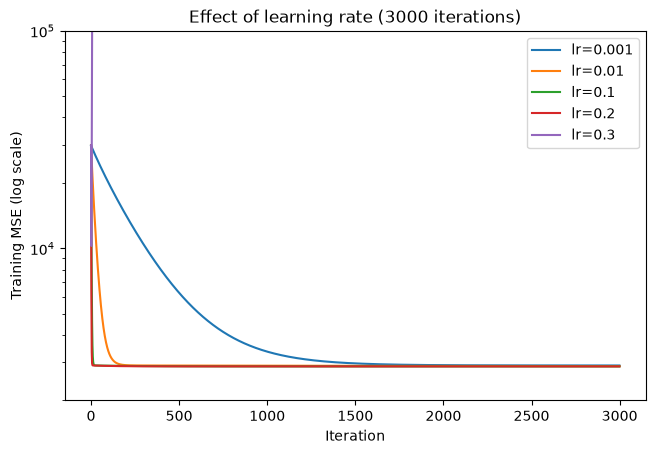

,lr,final_loss,status
0,0.001,2897.021945,converging
1,0.010,2878.947326,converging
2,0.100,2868.550185,converging
3,0.200,2868.549703,converging
4,0.300,NaN,diverged


In [8]:
lrs = [0.001, 0.01, 0.1, 0.2, 0.3]
plt.figure(figsize=(7.5, 4.8))
rows = []
for lr in lrs:
    with np.errstate(all="ignore"):
        w_, b_, L_, _ = gradient_descent(Xtr, ytr, lr, 3000)
    L_plot = np.where(np.isfinite(L_), L_, np.nan)
    plt.plot(L_plot, label=f"lr={lr}")
    rows.append({"lr": lr, "final_loss": L_[-1],
                 "status": "diverged" if (not np.isfinite(L_[-1]) or L_[-1] > L_[0]) else "converging"})
plt.yscale("log")
plt.ylim(2e3, 1e5)
plt.xlabel("Iteration")
plt.ylabel("Training MSE (log scale)")
plt.title("Effect of learning rate (3000 iterations)")
plt.legend()
plt.savefig("D:/Research Project/results/figures/gd_learning_rates.png", dpi=150, bbox_inches="tight")
plt.show()
pd.DataFrame(rows)

In [9]:
import sys; sys.path.append("../src")
from experiment_log import save_experiment_record, audit, lookup, NA

In [10]:
save_experiment_record(
    "exp5_gradient_descent", "Linear regression by gradient descent vs sklearn",
    dataset={"name": "sklearn load_diabetes", "n_train": len(Xtr), "n_test": len(Xte)},
    preprocessing="StandardScaler fitted on the training rows only, applied to train and test; target left unscaled",
    seeds={"train_test_split": 42},
    models={"gradient_descent": {"learning_rate": LR, "iterations": N_ITER, "init": "zeros", "loss": "MSE"},
            "sklearn_LinearRegression": "default, same standardized data",
            "learning_rates_tested": lrs},
    train_test_protocol="Same 80/20 split as the baseline (random_state=42)",
    cv_protocol=NA + ": no hyperparameter selection; learning rate and iterations set by hand",
    metrics=metrics,
    tables=["gd_vs_sklearn_coefficients.csv", "gd_vs_sklearn_metrics.csv"],
    figures=["gd_loss_curve.png", "gd_coef_distance.png", "gd_learning_rates.png"],
    observation="Gradient descent reached essentially the same solution and test performance as sklearn. Coefficients converged more slowly than the loss because of correlated features, and learning rates above the stability limit diverged.",
)

Saved results/experiments/exp5_gradient_descent.json and .md


{'exp_id': 'exp5_gradient_descent',
 'title': 'Linear regression by gradient descent vs sklearn',
 'created': '2026-10-13T01:30:51',
 'dataset': {'name': 'sklearn load_diabetes', 'n_train': 353, 'n_test': 89},
 'preprocessing': 'StandardScaler fitted on the training rows only, applied to train and test; target left unscaled',
 'seeds': {'train_test_split': 42},
 'models': {'gradient_descent': {'learning_rate': 0.1,
   'iterations': 10000,
   'init': 'zeros',
   'loss': 'MSE'},
  'sklearn_LinearRegression': 'default, same standardized data',
  'learning_rates_tested': [0.001, 0.01, 0.1, 0.2, 0.3]},
 'train_test_protocol': 'Same 80/20 split as the baseline (random_state=42)',
 'cv_protocol': 'not applicable: no hyperparameter selection; learning rate and iterations set by hand',
 'metrics': [{'train_MSE': 2868.5497028355776,
   'test_RMSE': 53.85344583676593,
   'test_R2': 0.4526027629719195},
  {'train_MSE': 2868.5497028355776,
   'test_RMSE': 53.85344583375748,
   'test_R2': 0.45260276